# Identification des utilisateurs de Copilot 

**Objectif.** Reconnaître, parmi **247 utilisateurs**, l'auteur d'une session de l'interface Copilot à partir de la suite de ses actions.
Mesure de qualité : **F1-macro**.

Ce notebook reconstruit la solution, celle qui obtient **1,000** sur le classement public Kaggle.

| Étape | Ce qu'elle fait |
|---|---|
| 1. Chargement | lire les fichiers CSV |
| 2. Exploration (EDA) | comprendre les données, avec des graphiques |
| 3. Prétraitement | nettoyer les actions et construire plusieurs *vues* texte |
| 4. Vectorisation TF-IDF | transformer le texte en nombres |
| 5. Augmentation | découper les sessions d'entraînement en morceaux |
| 6. Modèles de base | 3 SVM linéaires + 1 plus proche voisin |
| 7. Validation croisée imbriquée | mesurer honnêtement et préparer le stacking |
| 8. Stacking | une régression logistique combine les 4 modèles |
| 9. Analyse des erreurs | où le modèle se trompe-t-il ? |
| 10. Équilibrage (Sinkhorn) | corriger les prédictions pour respecter la part de chaque utilisateur |
| 11. Diagnostic du test | vérifier que l'équilibrage est justifié |
| 12. Modèle final et soumission | `submission28_a1.csv` |



### Comment l'exécuter
1. Placer `train.csv` et `test.csv` (et éventuellement `sample_submission.csv`) dans le même dossier que ce notebook.
2. Menu **Run All** (Exécuter tout).
3. Durée : environ **1 h à 1 h 30** sur un ordinateur portable (26 entraînements de 3 SVM). Pendant l'exécution, empêcher la mise en veille de l'ordinateur.

Le notebook crée lui-même un dossier `nb28_checkpoints/` où il sauvegarde chaque entraînement terminé : si l'exécution est interrompue, il suffit de relancer **Run All**, et il reprend là où il s'était arrêté. Ce dossier est produit par le notebook (rien n'est importé de l'extérieur) ; on peut le supprimer pour tout recalculer.

## 0. Bibliothèques et réglages


In [1]:
import re
import time
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack, vstack, csr_matrix

from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ---------------- réglages de la solution ----------------
SEED = 42            # graine des modèles (SVM, régression logistique)
OSEED = 123          # graine des 5 plis externes de la validation croisée
OUTER_SPLITS = 5     # plis externes
INNER_SPLITS = 4     # plis internes (pour entraîner le méta-modèle)
SVM_C = 0.5          # régularisation des SVM
META_C = 3.0         # régularisation du méta-modèle
W_CHUNK = 0.5        # poids des morceaux de sessions
MIN_CHUNK = 10       # nombre minimal d'actions dans un morceau
RARE_N = 10          # utilisateur "rare" : au plus 10 sessions dans le pli d'entraînement
ALPHA_FINAL = 1.0    # force de l'équilibrage de Sinkhorn retenu (a = 1)
N_DRAWS = 400        # tirages pour les scénarios S2 / S3
RUN_ABLATION = True  # entraîne aussi des SVM simples pour montrer l'apport de chaque idée (~5 min)

DATA_DIR = Path.cwd()
assert (DATA_DIR / "train.csv").exists() and (DATA_DIR / "test.csv").exists(), \
    "Placez train.csv et test.csv dans le dossier du notebook."
CKPT = DATA_DIR / "nb28_checkpoints"
CKPT.mkdir(exist_ok=True)
print("Dossier :", DATA_DIR)

Dossier : /Users/mac/Downloads/BE-Data_Science/Be-best-solution


## 1. Chargement des données

Chaque ligne est une **session** :

```
train.csv : utilisateur, navigateur, action_1, action_2, ...
test.csv  :              navigateur, action_1, action_2, ...
```



In [2]:
def load_raw(path, has_user=True):
    records = []
    with open(path, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            line = line.strip()
            if not line:
                continue
            fields = line.split(",")
            records.append({
                "row_id": i + 1,
                "user": fields[0] if has_user else None,
                "browser": fields[1] if has_user else fields[0],
                "actions": fields[2:] if has_user else fields[1:],
            })
    return records


train_raw = load_raw(DATA_DIR / "train.csv", True)
test_raw = load_raw(DATA_DIR / "test.csv", False)
ntr, nte = len(train_raw), len(test_raw)
n_all = ntr + nte
print(f"Sessions d'entraînement : {ntr}")
print(f"Sessions de test        : {nte}")
print(f"Utilisateurs distincts  : {len(set(r['user'] for r in train_raw))}")

ex = train_raw[0]
print("\nExemple : utilisateur =", ex["user"], "| navigateur =", ex["browser"], "|", len(ex["actions"]), "champs")
for a in ex["actions"][:8]:
    print("   ", a)

Sessions d'entraînement : 3279
Sessions de test        : 324
Utilisateurs distincts  : 247

Exemple : utilisateur = nuh | navigateur = Firefox | 3128 champs
    Création d'un écran(infologic.core.accueil.AccueilController)
    Affichage d'une dialogue
    Exécution d'un bouton
    Fermeture d'une dialogue
    Affichage d'une dialogue
    Exécution d'un bouton
    Fermeture d'une dialogue
    Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow)


## 2. Exploration des données (EDA)

Avant de modéliser, on regarde les données : combien de sessions par utilisateur, quelle longueur, quels types d'actions.
Ces constats expliquent plusieurs choix de la solution.

count    247.0
mean      13.3
std        8.9
min        4.0
25%        7.0
50%       12.0
75%       16.0
max       75.0
Name: count, dtype: float64


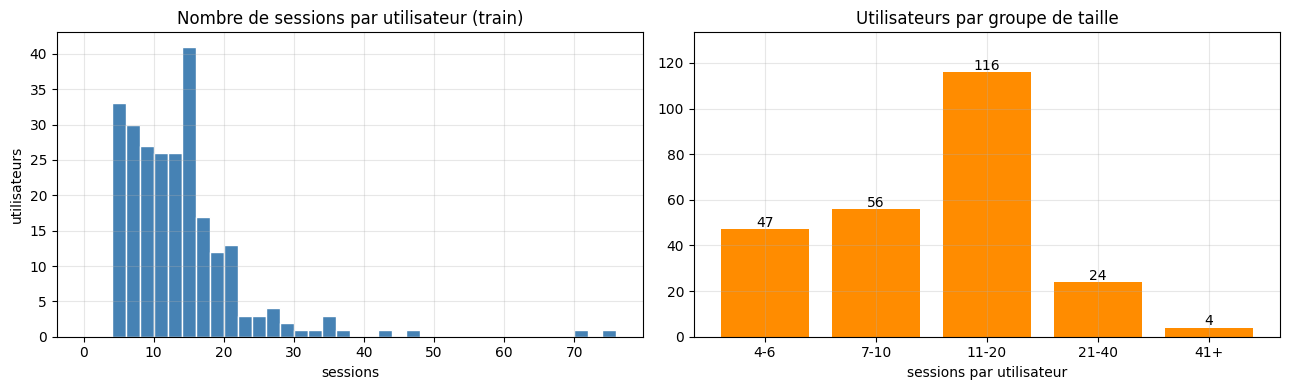

In [3]:
users = pd.Series([r["user"] for r in train_raw])
per_user = users.value_counts()
print(per_user.describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(per_user.values, bins=range(0, per_user.max() + 3, 2), color="steelblue", edgecolor="white")
ax[0].set_title("Nombre de sessions par utilisateur (train)")
ax[0].set_xlabel("sessions"); ax[0].set_ylabel("utilisateurs")
bins = [3, 6, 10, 20, 40, 1000]
labels = ["4-6", "7-10", "11-20", "21-40", "41+"]
grp = pd.cut(per_user, bins=bins, labels=labels).value_counts().reindex(labels)
ax[1].bar(labels, grp.values, color="darkorange")
for i, v in enumerate(grp.values):
    ax[1].text(i, v + 1, str(v), ha="center")
ax[1].set_ylim(0, grp.max() * 1.15)
ax[1].set_title("Utilisateurs par groupe de taille"); ax[1].set_xlabel("sessions par utilisateur")
plt.tight_layout(); plt.show()

**Constat 1 — déséquilibre.** Certains utilisateurs ont 4 sessions, d'autres plus de 70. Le **F1-macro** donne le même poids à chaque utilisateur : se tromper sur un utilisateur rare coûte autant que se tromper sur un utilisateur fréquent, alors qu'on a beaucoup moins d'exemples pour l'apprendre. D'où deux choix plus loin : `class_weight="balanced"` dans les modèles, et l'augmentation renforcée pour les utilisateurs rares.

Jetons temporels t1, t2... : 568267 sur 3053110 champs (18.6%)
Longueur des sessions (actions réelles) : médiane 343, min 0, max 11977


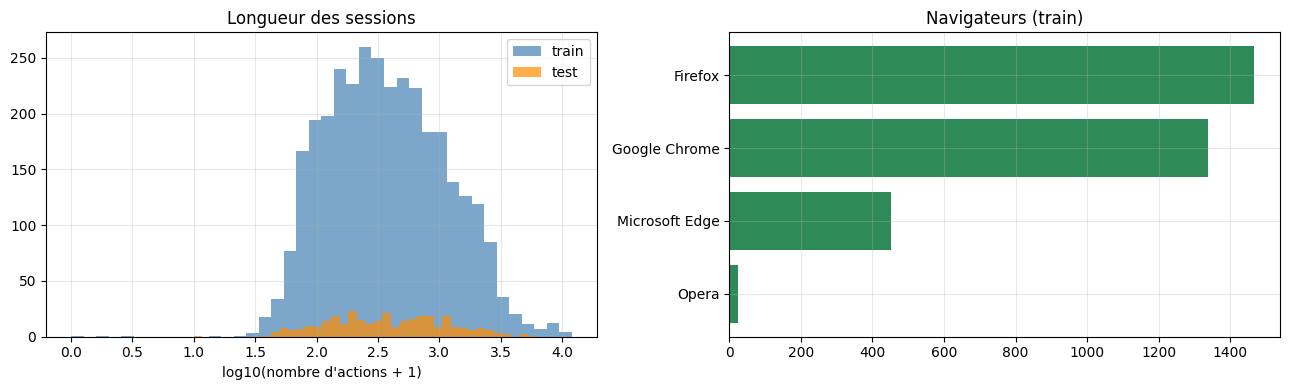

In [ ]:
RE_TIME = re.compile(r'^t\d+$') # motif d'un jeton temporel : "t" suivi de chiffres (t1, t2, t15...)
RE_MODULE = re.compile(r'\(([^)]+)\)') # motif d'un module : le texte entre parenthèses ( ... )
RE_SCREEN = re.compile(r'<([^>]+)>')    # motif d'un écran : le texte entre chevrons < ... >

all_actions = [r["actions"] for r in train_raw + test_raw]
n_time = sum(1 for acts in all_actions for a in acts if RE_TIME.match(a))
n_tot = sum(len(acts) for acts in all_actions)
real_lens = np.array([sum(1 for a in acts if not RE_TIME.match(a)) for acts in all_actions])
print(f"Jetons temporels t1, t2... : {n_time} sur {n_tot} champs ({n_time / n_tot:.1%})")
print(f"Longueur des sessions (actions réelles) : médiane {np.median(real_lens):.0f}, "
      f"min {real_lens.min()}, max {real_lens.max()}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(np.log10(real_lens[:ntr] + 1), bins=40, alpha=0.7, label="train", color="steelblue")
ax[0].hist(np.log10(real_lens[ntr:] + 1), bins=40, alpha=0.7, label="test", color="darkorange")
ax[0].set_xlabel("log10(nombre d'actions + 1)"); ax[0].set_title("Longueur des sessions"); ax[0].legend()
br = pd.Series([r["browser"] for r in train_raw]).value_counts()
ax[1].barh(br.index[::-1], br.values[::-1], color="seagreen"); ax[1].set_title("Navigateurs (train)")
plt.tight_layout(); plt.show()

**Constat 2 — sessions longues.** La plupart des sessions contiennent des centaines d'actions. On peut donc les **découper en morceaux** qui restent informatifs : c'est l'idée de l'augmentation.

Actions complètes distinctes : 7293
Types d'action (action de base) distincts : 45
Actions avec module (...) : 12.7%
Actions avec écran <...>  : 4.6%


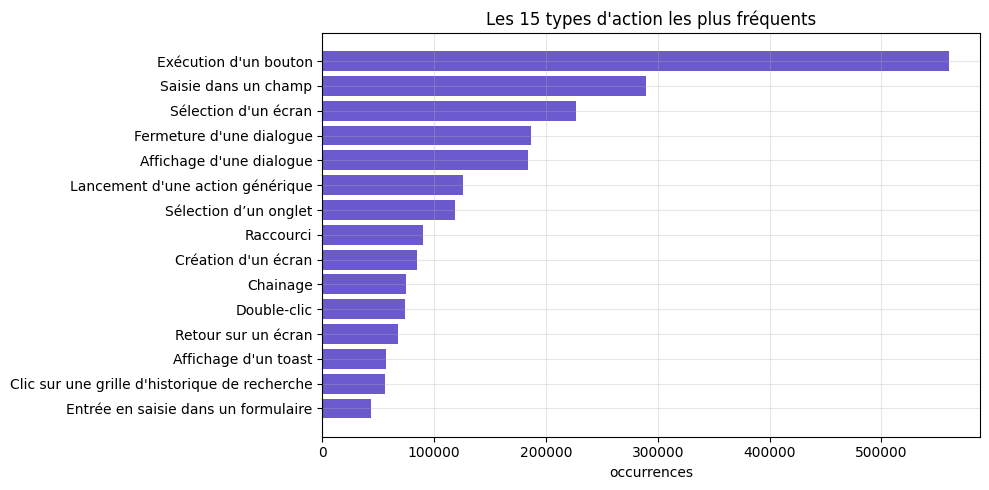

In [5]:
def get_action_base(a):
    # action sans module (...), écran <...> ni texte $...$, sans "1" final
    return re.sub(r'[\(\<\$].*?[\)\>\$]', '', a).rstrip('1').strip()


real_flat = [a for acts in all_actions for a in acts if not RE_TIME.match(a)]
base_counts = Counter(get_action_base(a) for a in real_flat)
print(f"Actions complètes distinctes : {len(set(real_flat))}")
print(f"Types d'action (action de base) distincts : {len(base_counts)}")
print(f"Actions avec module (...) : {np.mean([bool(RE_MODULE.search(a)) for a in real_flat]):.1%}")
print(f"Actions avec écran <...>  : {np.mean([bool(RE_SCREEN.search(a)) for a in real_flat]):.1%}")

top = base_counts.most_common(15)
plt.figure(figsize=(10, 5))
plt.barh([t[:45] for t, _ in top][::-1], [c for _, c in top][::-1], color="slateblue")
plt.title("Les 15 types d'action les plus fréquents"); plt.xlabel("occurrences")
plt.tight_layout(); plt.show()

**Constat 3 — une action est riche.** Une action comme `Création d'un écran(infologic.core.gui...InputFormNestedWindow)` combine un **type d'action**, un **module** logiciel (entre parenthèses) et parfois un **écran** (entre chevrons). Les habitudes d'un utilisateur se voient à la fois dans les actions elles-mêmes et dans leurs **enchaînements**.

## 3. Prétraitement : construire plusieurs « vues » de chaque session

1. On **retire les jetons temporels** `t1`, `t2`… : des essais ont montré qu'ils n'apportent rien.
2. On construit cinq **vues texte** de la même session :

| Vue | Contenu | Pourquoi |
|---|---|---|
| `raw` | actions complètes | l'information brute |
| `trans` | actions de base (sans module ni écran) | généralise : « cliquer sur un bouton », quel que soit le module |
| `modules` | suite des modules (dernier élément du chemin) | le « parcours » dans l'application |
| `u_full` | **chaque action complète = un seul mot** (espaces remplacés par `_`) | permet de capter les enchaînements exacts « cette action, puis celle-là »  |
| `u_base` | chaque action de base = un seul mot | enchaînements de types d'actions |

Pourquoi `u_full` ? Par défaut, l'outil TF-IDF coupe le texte aux espaces **et** à la ponctuation : une action est éclatée en sous-mots (`création`, `un`, `écran`, `infologic`…), et les paires de mots voisins mélangent la fin d'une action et le début de la suivante. En faisant de chaque action un seul mot, une paire de mots devient exactement une **transition entre deux actions**.

In [6]:
def get_short_module(m):
    return m.split('.')[-1]


def unit(a):
    # une action = un seul "mot"
    return re.sub(r"\s+", "_", a)


def make_views(real):
    mods = [get_short_module(RE_MODULE.search(a).group(1)) for a in real if RE_MODULE.search(a)]
    return {
        "raw": " ".join(real),
        "trans": " ".join(get_action_base(a) for a in real),
        "modules": " ".join(mods),
        "u_full": " ".join(unit(a) for a in real),
        "u_base": " ".join(unit(get_action_base(a)) for a in real),
    }


all_real = [[a for a in r["actions"] if not RE_TIME.match(a)] for r in train_raw + test_raw]
df = pd.DataFrame([make_views(real) for real in all_real])
browsers = [r["browser"] for r in train_raw + test_raw]

le = LabelEncoder()
y = le.fit_transform([r["user"] for r in train_raw])   # utilisateur -> numéro 0..246
n_classes = len(le.classes_)
print("Classes :", n_classes)

demo = make_views(all_real[0][:3])
for k, v in demo.items():
    print(f"{k:8s}: {v[:160]}")

Classes : 247
raw     : Création d'un écran(infologic.core.accueil.AccueilController) Affichage d'une dialogue Exécution d'un bouton
trans   : Création d'un écran Affichage d'une dialogue Exécution d'un bouton
modules : AccueilController
u_full  : Création_d'un_écran(infologic.core.accueil.AccueilController) Affichage_d'une_dialogue Exécution_d'un_bouton
u_base  : Création_d'un_écran Affichage_d'une_dialogue Exécution_d'un_bouton


## 4. Vectorisation TF-IDF : du texte aux nombres

Un modèle ne manipule que des nombres. Pour chaque vue, on compte les **n-grammes** (suites de *n* éléments consécutifs) et on les pondère par **TF-IDF** :

$$\text{tfidf}(t,d) = \underbrace{(1+\ln \text{tf}(t,d))}_{\text{fréquence dans la session}} \times \underbrace{\left(\ln\frac{1+N}{1+\text{df}(t)}+1\right)}_{\text{rareté dans l'ensemble}}$$

- un élément fréquent **dans la session** mais rare **dans l'ensemble** reçoit un poids élevé : il est distinctif ;
- `sublinear_tf` remplace le compte par $1+\ln(\text{tf})$ : une action répétée 50 fois ne pèse pas 50 fois plus ;
- chaque vecteur est normalisé : sessions longues et courtes deviennent comparables.

| Vue | n-grammes | Taille max du vocabulaire |
|---|---|---|
| `raw` (mots) | 1–2 mots | 15 000 |
| `raw` (caractères) | 3–5 caractères | 15 000 |
| `trans` | 1–3 mots | 5 000 |
| `modules` | 1–2 mots | 3 000 |
| `u_full` | **1–3 actions entières** | 50 000 |
| `u_base` | **1–4 actions de base** | 30 000 |

Le vocabulaire et les poids IDF sont calculés sur les textes du train **et** du test : cette étape n'utilise **aucune étiquette** (non supervisée), il n'y a donc pas de fuite des réponses.

On forme trois matrices :
- **A** = navigateur + `raw` + `trans` + `modules` ;
- **U** = navigateur + `u_full` + `u_base` (actions entières) ;
- **A+U** = tout.

In [7]:
atom = dict(token_pattern=r"\S+", lowercase=False, min_df=2)   # découpe UNIQUEMENT aux espaces
SPECS = [
    ("raw_w", "raw", dict(ngram_range=(1, 2), max_features=15000)),
    ("raw_c", "raw", dict(ngram_range=(3, 5), max_features=15000, analyzer="char_wb")),
    ("trans", "trans", dict(ngram_range=(1, 3), max_features=5000)),
    ("mods", "modules", dict(ngram_range=(1, 2), max_features=3000)),
    ("u_full", "u_full", dict(ngram_range=(1, 3), max_features=50000, **atom)),
    ("u_base", "u_base", dict(ngram_range=(1, 4), max_features=30000, **atom)),
]
t0 = time.time()
browser_ohe = csr_matrix(pd.get_dummies(pd.Series(browsers)).values.astype(float))   # navigateur en 0/1
vecs, mats = {}, {}
for name, col, kw in SPECS:
    v = TfidfVectorizer(sublinear_tf=True, **kw)
    mats[name] = v.fit_transform(df[col]).tocsr()
    vecs[name] = v
    print(f"  {name:7s}: {mats[name].shape[1]:>6} colonnes")

nb = browser_ohe.shape[1]
sizes = {n: mats[n].shape[1] for n, _, _ in SPECS}
end_A = nb + sizes["raw_w"] + sizes["raw_c"] + sizes["trans"] + sizes["mods"]
n_cols = end_A + sizes["u_full"] + sizes["u_base"]
IDX_A = np.arange(0, end_A)
IDX_U = np.r_[np.arange(0, nb), np.arange(end_A, n_cols)]

XAU = hstack([browser_ohe] + [mats[n] for n, _, _ in SPECS]).tocsr()
XA = XAU[:, IDX_A].tocsr()
XUo = XAU[:, IDX_U].tocsr()
XTXT = normalize(XAU[:, nb:].tocsr())          # pour le plus proche voisin (sans le navigateur)
print(f"\nA : {XA.shape} | U + navigateur : {XUo.shape} | A+U : {XAU.shape}  ({time.time() - t0:.0f}s)")
print(f"Proportion de valeurs non nulles dans A+U : {XAU.nnz / (XAU.shape[0] * XAU.shape[1]):.4%}  -> matrice creuse")

  raw_w  :  10185 colonnes
  raw_c  :  15000 colonnes
  trans  :   2253 colonnes
  mods   :   3000 colonnes
  u_full :  50000 colonnes
  u_base :  30000 colonnes

A : (3603, 30442) | U + navigateur : (3603, 80004) | A+U : (3603, 110442)  (48s)
Proportion de valeurs non nulles dans A+U : 2.7878%  -> matrice creuse


In [8]:
# Quels n-grammes d'actions entières sont les plus caractéristiques d'un utilisateur ?
v_uf = vecs["u_full"]
vocab = np.array(v_uf.get_feature_names_out())
u0 = np.where(y == y[0])[0]
mean_u = np.asarray(mats["u_full"][u0].mean(axis=0)).ravel()
mean_all = np.asarray(mats["u_full"][:ntr].mean(axis=0)).ravel()
spec = mean_u - mean_all
print(f"Utilisateur {le.classes_[y[0]]} ({len(u0)} sessions) : n-grammes d'actions les plus spécifiques")
for j in np.argsort(-spec)[:8]:
    print(f"   {spec[j]:+.3f}  {vocab[j][:120]}")

Utilisateur nuh (11 sessions) : n-grammes d'actions les plus spécifiques
   +0.106  Affichage_d'un_toast Filtrage_/_Tri
   +0.090  Double-clic(MAINT) Lancement_d'une_action_générique Affichage_d'une_dialogue
   +0.085  Exécution_d'un_bouton Affichage_d'un_toast Filtrage_/_Tri
   +0.085  Exécution_d'un_bouton$JCP$ Affichage_d'un_toast
   +0.084  Fermeture_d'une_dialogue$JCP$
   +0.084  Exécution_d'un_bouton$JCP$
   +0.083  Affichage_d'une_dialogue$JCP$
   +0.081  Affichage_d'un_toast Filtrage_/_Tri Exécution_d'un_bouton


## 5. Augmentation des données : découper les sessions d'entraînement

**Idée.** Une session de 300 actions découpée en 3 tiers donne 3 mini-sessions, toujours produites par la même personne. Un utilisateur qui n'a que 4 sessions d'entraînement dispose ainsi de 4 + 12 = 16 exemples.

- **Tiers** pour toutes les sessions d'entraînement (au moins 3 × 10 actions).
- **Cinquièmes** en plus pour les **utilisateurs rares** (au plus 10 sessions dans le pli d'entraînement), là où le F1-macro perd le plus.
- Les morceaux reçoivent un **poids de 0,5** : ils aident sans dominer les vraies sessions.
- Les morceaux sont vectorisés avec **les mêmes vocabulaires** que les sessions complètes.

**Précaution essentielle :** on ne découpe que l'entraînement. Les sessions de validation et de test restent **complètes**. Dans chaque pli, seuls les morceaux des sessions d'entraînement de ce pli sont ajoutés : aucune fuite.



Tiers : 9816 morceaux | cinquièmes : 16160 morceaux (109s)


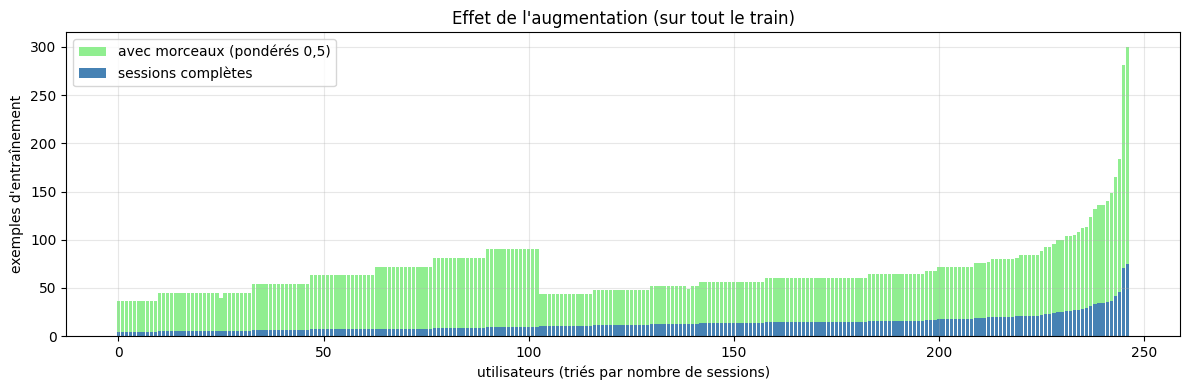

In [9]:
def build_chunks(n_parts):
    texts = {c: [] for c in ["raw", "trans", "modules", "u_full", "u_base"]}
    parents = []
    for i in range(ntr):                     # uniquement les sessions d'ENTRAÎNEMENT
        real = all_real[i]
        n = len(real)
        if n < n_parts * MIN_CHUNK:
            continue
        cuts = [round(n * k / n_parts) for k in range(n_parts + 1)]
        for k in range(n_parts):
            v = make_views(real[cuts[k]:cuts[k + 1]])
            for c in texts:
                texts[c].append(v[c])
            parents.append(i)                # session d'origine du morceau
    parents = np.array(parents)
    X = hstack([browser_ohe[parents]] + [vecs[nm].transform(texts[col]) for nm, col, _ in SPECS]).tocsr()
    return X, parents


t0 = time.time()
XC3, PAR3 = build_chunks(3)
XC5, PAR5 = build_chunks(5)
XC3_A, XC3_U = XC3[:, IDX_A].tocsr(), XC3[:, IDX_U].tocsr()
XC5_A, XC5_U = XC5[:, IDX_A].tocsr(), XC5[:, IDX_U].tocsr()
print(f"Tiers : {XC3.shape[0]} morceaux | cinquièmes : {XC5.shape[0]} morceaux ({time.time() - t0:.0f}s)")

cnt = np.bincount(y, minlength=n_classes)
rare = cnt <= RARE_N
ex_before = cnt
ex_after = cnt + np.bincount(y[PAR3], minlength=n_classes) + np.where(rare, np.bincount(y[PAR5], minlength=n_classes), 0)
order = np.argsort(cnt)
plt.figure(figsize=(12, 4))
plt.bar(range(n_classes), ex_after[order], color="lightgreen", label="avec morceaux (pondérés 0,5)")
plt.bar(range(n_classes), ex_before[order], color="steelblue", label="sessions complètes")
plt.xlabel("utilisateurs (triés par nombre de sessions)"); plt.ylabel("exemples d'entraînement")
plt.title("Effet de l'augmentation (sur tout le train)"); plt.legend(); plt.tight_layout(); plt.show()

## 6. Les modèles de base

### SVM linéaire (`LinearSVC`)
Pour chaque utilisateur, un SVM cherche une **frontière** (un hyperplan dans l'espace des 110 000 colonnes) qui sépare ses sessions de celles des autres, avec la **marge** la plus large possible (stratégie « un contre tous » : 247 frontières). Il donne un **score** par utilisateur ; le plus élevé gagne.
- `C = 0,5` : compromis entre coller aux données et rester simple (réglage vérifié par la solution 20) ;
- `class_weight="balanced"` : chaque session d'un utilisateur rare compte plus, pour compenser le déséquilibre.

On entraîne **trois** SVM sur trois représentations différentes, ce qui leur fait commettre des erreurs différentes :

| Nom | Caractéristiques |
|---|---|
| `svc_A` | A (vues de la solution 7) |
| `svc_AU` | A+U (tout) |
| `svc_U` | U + navigateur (actions entières) |

### Plus proche voisin par utilisateur (`nn`)
Pour une session et un utilisateur, on prend la **similarité cosinus** avec la session la plus ressemblante de cet utilisateur. Faible seul, mais il raisonne autrement (« cette session ressemble beaucoup à une session de X ») et aide pour les utilisateurs rares.

In [10]:
def _chk(m):
    assert len(m.classes_) == n_classes, "une classe manque dans le train"


def svc_rare(Xfull, X3, X5, tr_idx, y_tr, ev_idx):
    # SVM entraîné sur : sessions complètes + tiers (tous) + cinquièmes (utilisateurs rares du pli)
    mk3 = np.isin(PAR3, tr_idx)
    cnt_tr = np.bincount(y_tr, minlength=n_classes)
    rare_par = tr_idx[cnt_tr[y_tr] <= RARE_N]
    mk5 = np.isin(PAR5, rare_par)
    X = vstack([Xfull[tr_idx], X3[mk3], X5[mk5]]).tocsr()
    yy = np.concatenate([y_tr, y[PAR3[mk3]], y[PAR5[mk5]]])
    sw = np.concatenate([np.ones(len(tr_idx)), np.full(int(mk3.sum()), W_CHUNK), np.full(int(mk5.sum()), W_CHUNK)])
    m = LinearSVC(C=SVM_C, class_weight="balanced", max_iter=3000, random_state=SEED)
    m.fit(X, yy, sample_weight=sw)
    _chk(m)
    return m.decision_function(Xfull[ev_idx])          # on prédit des sessions COMPLÈTES


def nn_scores(tr_idx, y_tr, ev_idx):
    S = (XTXT[ev_idx] @ XTXT[tr_idx].T).toarray()      # similarités cosinus
    nn = np.full((len(ev_idx), n_classes), -1.0)
    for c in range(n_classes):
        mk = (y_tr == c)
        if mk.any():
            nn[:, c] = S[:, mk].max(axis=1)
    return nn


KEYS = ["R_svc_A", "R_svc_AU", "R_svc_U", "nn"]


def fit_base(tr_idx, y_tr, ev_idx):
    # entraîne les 4 modèles sur tr_idx et renvoie leurs scores (n_eval x 247) sur ev_idx
    return {
        "R_svc_A": svc_rare(XA, XC3_A, XC5_A, tr_idx, y_tr, ev_idx),
        "R_svc_AU": svc_rare(XAU, XC3, XC5, tr_idx, y_tr, ev_idx),
        "R_svc_U": svc_rare(XUo, XC3_U, XC5_U, tr_idx, y_tr, ev_idx),
        "nn": nn_scores(tr_idx, y_tr, ev_idx),
    }


def fit_base_ckpt(key, tr_idx, y_tr, ev_idx):
    # même chose, avec sauvegarde (reprise automatique si le notebook est interrompu)
    path = CKPT / f"{key}.npz"
    if path.exists():
        z = np.load(path)
        return {k: z[k] for k in KEYS}
    t0 = time.time()
    out = fit_base(tr_idx, y_tr, ev_idx)
    np.savez_compressed(path, **out)
    print(f"     {key}: {time.time() - t0:.0f}s")
    return out

## 7. Validation croisée imbriquée

**Pourquoi.** On veut (1) **mesurer** le score honnêtement, sur des sessions jamais vues, et (2) entraîner un **méta-modèle** qui combine les 4 modèles (stacking, section 8). Le méta-modèle doit apprendre sur des scores produits par des modèles qui **n'ont pas vu** les sessions concernées (scores *hors pli*), sinon il apprendrait à faire confiance à des scores trop beaux.

**Comment.**
- **5 plis externes** stratifiés (graine 123) : chaque pli sert une fois de validation (environ 20 % du train). On entraîne les modèles sur les 80 % restants et on note le pli de validation → ces notes servent à **mesurer**.
- À l'intérieur de chaque pli externe, **4 plis internes** (graine 124) : on produit des scores hors pli sur toute la partie d'entraînement → ces notes servent à **entraîner le méta-modèle**.

Stratifié = chaque pli garde à peu près la proportion de chaque utilisateur.

Total : 5 + 5 × 4 = **25 entraînements** des 4 modèles (+ 1 entraînement final sur tout le train à la section 12). C'est l'étape longue du notebook.

In [11]:
outer = list(StratifiedKFold(OUTER_SPLITS, shuffle=True, random_state=OSEED).split(np.zeros(ntr), y))
oof_outer = {k: np.zeros((ntr, n_classes)) for k in KEYS}   # scores hors pli (plis externes)
inner_oof = []                                              # scores hors pli internes, par pli externe
T0 = time.time()
for f, (tr, va) in enumerate(outer):
    print(f"=== Pli externe {f + 1}/{OUTER_SPLITS} : {len(tr)} sessions d'entraînement, {len(va)} de validation")
    sc_va = fit_base_ckpt(f"s{OSEED}_outer{f}", tr, y[tr], va)
    for k in KEYS:
        oof_outer[k][va] = sc_va[k]
    inner = list(StratifiedKFold(INNER_SPLITS, shuffle=True, random_state=OSEED + 1).split(np.zeros(len(tr)), y[tr]))
    oof_in = {k: np.zeros((len(tr), n_classes)) for k in KEYS}
    for j, (itr, iva) in enumerate(inner):
        sc_in = fit_base_ckpt(f"s{OSEED}_outer{f}_inner{j}", tr[itr], y[tr][itr], tr[iva])
        for k in KEYS:
            oof_in[k][iva] = sc_in[k]
    inner_oof.append(oof_in)
print(f"\nValidation croisée imbriquée terminée ({(time.time() - T0) / 60:.1f} min)")

=== Pli externe 1/5 : 2623 sessions d'entraînement, 656 de validation
=== Pli externe 2/5 : 2623 sessions d'entraînement, 656 de validation
=== Pli externe 3/5 : 2623 sessions d'entraînement, 656 de validation
=== Pli externe 4/5 : 2623 sessions d'entraînement, 656 de validation
=== Pli externe 5/5 : 2624 sessions d'entraînement, 655 de validation

Validation croisée imbriquée terminée (0.0 min)


In [12]:
def mf1(yt, yp):
    return f1_score(yt, yp, average="macro")


print("F1-macro de chaque modèle de base SEUL (plis externes) :")
base_f1 = {}
for k in KEYS:
    s = [mf1(y[va], oof_outer[k][va].argmax(1)) for _, va in outer]
    base_f1[k] = s
    print(f"  {k:9s} " + " ".join(f"{x:.4f}" for x in s) + f" | moyenne {np.mean(s):.4f}")

F1-macro de chaque modèle de base SEUL (plis externes) :
  R_svc_A   0.9548 0.9709 0.9582 0.9736 0.9778 | moyenne 0.9671
  R_svc_AU  0.9563 0.9859 0.9678 0.9759 0.9786 | moyenne 0.9729
  R_svc_U   0.9493 0.9601 0.9667 0.9674 0.9647 | moyenne 0.9616
  nn        0.8982 0.8830 0.9218 0.9169 0.9039 | moyenne 0.9048


## 8. Le stacking : un méta-modèle combine les 4 modèles

Le **méta-modèle** est une **régression logistique** : elle reçoit, pour chaque session, les 4 × 247 = 988 scores des modèles de base et produit une **probabilité** pour chaque utilisateur (les 247 probabilités font 1). Contrairement à une moyenne fixe (*blending*), elle **apprend** comment combiner les modèles, et peut le faire différemment pour chaque utilisateur.

- Pour chaque pli externe : méta-modèle entraîné sur les scores hors pli **internes** → appliqué aux scores du pli de **validation**.
- `C = 3`, `class_weight="balanced"`.

On obtient, pour chacune des 3 279 sessions, des probabilités produites sans jamais avoir vu cette session : `OOF_P`.

In [13]:
def mx(sc):
    return np.hstack([sc[k] for k in KEYS])


def fit_meta(X, yy):
    m = LogisticRegression(C=META_C, class_weight="balanced", max_iter=500, random_state=SEED)
    m.fit(X, yy)
    _chk(m)
    return m


OOF_P = np.zeros((ntr, n_classes))
fold_pri = []                                   # proportions des utilisateurs dans chaque pli d'entraînement
for f, (tr, va) in enumerate(outer):
    meta = fit_meta(mx(inner_oof[f]), y[tr])
    OOF_P[va] = meta.predict_proba(mx({k: oof_outer[k][va] for k in KEYS}))
    fold_pri.append(np.bincount(y[tr], minlength=n_classes) / len(tr))

stack_f1 = [mf1(y[va], OOF_P[va].argmax(1)) for _, va in outer]
print("Stacking (sans équilibrage) : " + " ".join(f"{x:.4f}" for x in stack_f1) + f" | moyenne {np.mean(stack_f1):.4f}")
print("Attendu sur les vraies données : 0.9753")

Stacking (sans équilibrage) : 0.9752 0.9780 0.9768 0.9785 0.9682 | moyenne 0.9753
Attendu sur les vraies données : 0.9753


### Apport de chaque idée ( `RUN_ABLATION = True`)

Pour visualiser d'où vient le score, on entraîne aussi, **sur les mêmes plis externes**, deux SVM simples sans morceaux :
- SVM sur **A** seul (vues de la solution 7) ;
- SVM sur **A+U** (avec les actions entières).

Ces modèles ne servent qu'à la comparaison ; ils n'entrent pas dans la solution finale.

In [14]:
def svc_plain(Xfull, tr_idx, y_tr, ev_idx):
    m = LinearSVC(C=SVM_C, class_weight="balanced", max_iter=3000, random_state=SEED)
    m.fit(Xfull[tr_idx], y_tr)
    return m.decision_function(Xfull[ev_idx])


steps = {}
if RUN_ABLATION:
    for name, X in [("SVM sur A", XA), ("SVM sur A+U", XAU)]:
        path = CKPT / f"ablation_{name.replace(' ', '_').replace('+', 'p')}.npy"
        if path.exists():
            pred = np.load(path)
        else:
            pred = np.zeros(ntr, dtype=int)
            for tr, va in outer:
                pred[va] = svc_plain(X, tr, y[tr], va).argmax(1)
            np.save(path, pred)
        steps[name] = np.mean([mf1(y[va], pred[va]) for _, va in outer])
steps["SVM A+U + morceaux"] = np.mean(base_f1["R_svc_AU"])
steps["Stacking (4 modèles)"] = np.mean(stack_f1)
for k, v in steps.items():
    print(f"  {k:24s} {v:.4f}")

  SVM sur A                0.9628
  SVM sur A+U              0.9696
  SVM A+U + morceaux       0.9729
  Stacking (4 modèles)     0.9753


## 9. Analyse des erreurs

Où le modèle se trompe-t-il encore ? Deux questions :
1. Quand il se trompe, le bon utilisateur est-il proche (2e, 3e) ? → **exactitude top-k** ;
2. Les erreurs touchent-elles surtout les utilisateurs rares ?

Erreurs : 69 sur 3279
  bon utilisateur parmi les  1 premiers : 0.9790
  bon utilisateur parmi les  2 premiers : 0.9909
  bon utilisateur parmi les  3 premiers : 0.9933
  bon utilisateur parmi les  5 premiers : 0.9951
  bon utilisateur parmi les 10 premiers : 0.9976
        sessions  erreurs   taux
groupe                          
4-6          239        7  0.029
7-10         471        8  0.017
11-20       1700       31  0.018
21-40        635       10  0.016
41+          234       13  0.056


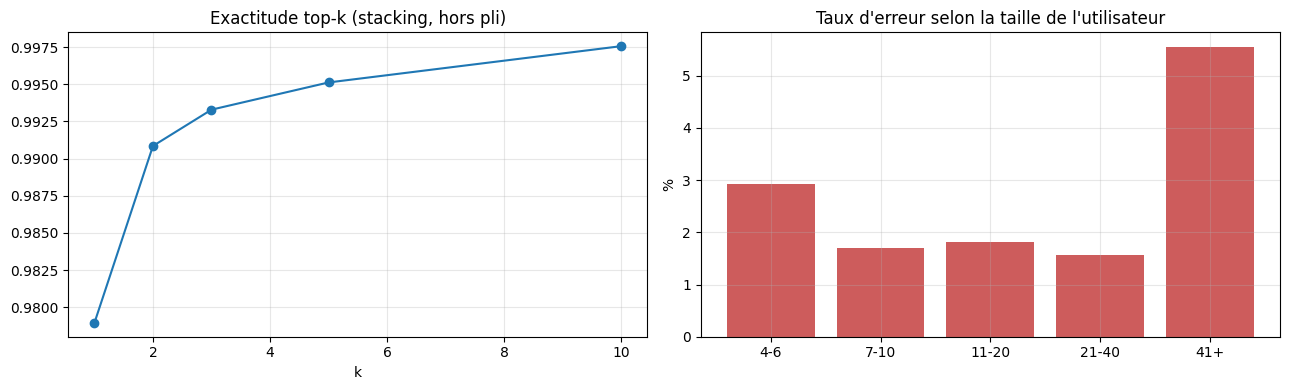

In [15]:
pred_stack = OOF_P.argmax(1)
err = pred_stack != y
rank = (OOF_P > OOF_P[np.arange(ntr), y][:, None]).sum(1)   # 0 = bon utilisateur en tête
print(f"Erreurs : {err.sum()} sur {ntr}")
for k in [1, 2, 3, 5, 10]:
    print(f"  bon utilisateur parmi les {k:2d} premiers : {np.mean(rank < k):.4f}")

size = pd.cut(cnt[y], bins=[3, 6, 10, 20, 40, 1000], labels=["4-6", "7-10", "11-20", "21-40", "41+"])
tab = pd.DataFrame({"groupe": size, "erreur": err}).groupby("groupe", observed=False)["erreur"].agg(["count", "sum", "mean"])
tab.columns = ["sessions", "erreurs", "taux"]
print(tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ks = [1, 2, 3, 5, 10]
ax[0].plot(ks, [np.mean(rank < k) for k in ks], "o-")
ax[0].set_title("Exactitude top-k (stacking, hors pli)"); ax[0].set_xlabel("k")
ax[1].bar(tab.index.astype(str), tab["taux"] * 100, color="indianred")
ax[1].set_title("Taux d'erreur selon la taille de l'utilisateur"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**Lecture.** Quand le modèle se trompe, le bon utilisateur est très souvent **deuxième** : le modèle hésite entre deux personnes. Un petit ajustement global des probabilités peut faire passer le bon utilisateur en tête : c'est l'idée de l'équilibrage.

## 10. L'équilibrage des prédictions : l'algorithme de Sinkhorn

### Pourquoi
L'analyse des erreurs a montré que, quand le modèle se trompe, le bon utilisateur est très souvent **deuxième** : le modèle hésite entre deux personnes.
Or le stacking prédit chaque session **séparément**, ce qui peut donner trop de sessions à un utilisateur et pas assez à un autre.

On connaît pourtant une information **globale** : la part $\pi_c$ de chaque utilisateur dans le train. Comme le test a été tiré en respectant ces proportions (vérifié dans la solution 28 : dispersion 38,4 pour le test, contre 39 pour un tirage stratifié et 221 pour un tirage au hasard), l'utilisateur $c$ devrait recevoir environ $e_c = n\,\pi_c$ des $n$ sessions à prédire.

### L'algorithme
On donne un **poids** $w_c$ (un « bouton de volume ») à chaque utilisateur :
1. au départ, tous les poids valent 1 ;
2. on multiplie les probabilités de chaque utilisateur par son poids, puis on remet chaque session à 100 % ;
3. on compte ce que chaque utilisateur reçoit au total ; on corrige son poids : $w_c \leftarrow w_c \times \dfrac{\text{attendu}}{\text{reçu}}$ (trop reçu → le poids baisse ; pas assez → il monte) ;
4. on répète 100 fois ;
5. chaque session va à l'utilisateur qui maximise $P_{ic} \times w_c^{\,a}$.



Le paramètre $a$ règle la **force** de la correction : $a = 1$ = correction complète ; $a = 0{,}5$ = correction à moitié.



In [16]:
def sinkhorn(P, target, alpha=1.0, n_iter=100):
    """Équilibrage de Sinkhorn.
    P      : probabilités (n_sessions x 247), chaque ligne somme à 1
    target : nombre de sessions attendu pour chaque utilisateur (e_c = n x part dans le train)
    alpha  : force de la correction (1 = complète, 0,5 = à moitié)
    n_iter : nombre d'itérations (100 suffisent pour converger)"""
    P = P + 1e-12                          # ajoute un nombre minuscule pour éviter les divisions par zéro
    w = np.ones(P.shape[1])                # un poids par utilisateur, égal à 1 au départ
    for _ in range(n_iter):                # on répète n_iter fois :
        Q = P * w                          #   1. applique les poids (chaque colonne x poids de l'utilisateur)
        Q /= Q.sum(1, keepdims=True)       #   2. remet chaque session (ligne) à une somme de 1
        w *= target / Q.sum(0)             #   3. corrige : poids x (attendu / reçu)
    return (P * w ** alpha).argmax(1)      # chaque session -> utilisateur qui maximise probabilité x poids^alpha

### Score en validation croisée : a = 1 et a = 0,5

On applique Sinkhorn sur chacun des 5 plis externes, aux probabilités hors pli du stacking (`OOF_P`, sessions que le modèle n'a jamais vues).
Pour chaque pli, le nombre attendu de chaque utilisateur est : nombre de sessions du pli × sa part dans la partie d'entraînement de ce pli (`fold_pri`).

Scores attendus sur les vraies données : sans équilibrage **0,9753** ; a = 0,5 **0,9827** ; a = 1 **0,9798**.

In [ ]:
scores = {"sans équilibrage": [mf1(y[va], OOF_P[va].argmax(1)) for _, va in outer]}   # F1 par pli, sans correction
for a in [1.0, 0.5]:                                       # les deux forces de correction testées
    scores[f"Sinkhorn a={a}"] = [                          # F1 par pli avec Sinkhorn
        mf1(y[va], sinkhorn(OOF_P[va], len(va) * fold_pri[f], alpha=a))   # attendu = taille du pli x parts de son entraînement
        for f, (_, va) in enumerate(outer)]
S1 = pd.DataFrame(scores, index=[f"pli {i + 1}" for i in range(OUTER_SPLITS)]).T   # tableau : méthodes x plis
S1["moyenne"] = S1.mean(1)                                 # moyenne des 5 plis = score de validation croisée
print("F1-macro sur les 5 plis externes (graine 123)")
print(S1.round(4))
print(f"\n(Sinkhorn a=1) : {S1.loc['Sinkhorn a=1.0', 'moyenne']:.4f} ")

F1-macro sur les 5 plis externes (graine 123)
                   pli 1   pli 2   pli 3   pli 4   pli 5  moyenne
sans équilibrage  0.9752  0.9780  0.9768  0.9785  0.9682   0.9753
Sinkhorn a=1.0    0.9799  0.9732  0.9840  0.9795  0.9825   0.9798
Sinkhorn a=0.5    0.9814  0.9814  0.9827  0.9834  0.9845   0.9827

Solution 28 (Sinkhorn a=1) : 0.9798   (attendu sur les vraies données : 0.9798)


## 11. Modèle final et soumission (a = 1)

1. Les 4 modèles de base sont entraînés sur **tout** le train et notent les 324 sessions de test.
2. Le méta-modèle est entraîné sur les scores hors pli des 3 279 sessions d'entraînement, puis donne les probabilités du test.
3. Sinkhorn avec **a = 1** équilibre ces probabilités : c'est la version qui obtient **1,000** sur le classement public Kaggle (a = 0,5 obtenait 0,993).

In [18]:
TR_ALL = np.arange(ntr)                                    # indices de toutes les sessions d'entraînement
TE_IDX = np.arange(ntr, n_all)                             # indices des sessions de test (après le train dans les matrices)
sc_test = fit_base_ckpt("full_fit_test", TR_ALL, y, TE_IDX)   # 4 modèles entraînés sur TOUT le train -> scores du test
meta_final = fit_meta(mx(oof_outer), y)                    # méta-modèle final, appris sur les scores hors pli
P_test = meta_final.predict_proba(mx(sc_test))             # probabilités du test (324 x 247)
pred0 = P_test.argmax(1)                                   # prédiction sans équilibrage (pour comparaison)

prior = np.bincount(y, minlength=n_classes) / ntr          # part de chaque utilisateur dans tout le train
pred = sinkhorn(P_test, nte * prior, alpha=ALPHA_FINAL)    # Sinkhorn a=1 ; attendu = 324 x part dans le train
labels = le.inverse_transform(pred)                        # numéros -> noms d'utilisateurs
sub = pd.DataFrame({"RowId": [r["row_id"] for r in test_raw], "prediction": labels})   # format Kaggle
sub.to_csv(DATA_DIR / "submission28_a1.csv", index=False)  # soumission finale
print(f"-> submission28_a1.csv écrit ({len(sub)} lignes)")
print(f"Sessions modifiées par l'équilibrage : {int((pred != pred0).sum())} sur {nte}")   # combien ont changé
print(sub.head())                                          # 5 premières lignes

ss = DATA_DIR / "sample_submission.csv"                    # fichier d'exemple Kaggle (facultatif)
if ss.exists():                                            # s'il est présent, on vérifie le format
    s = pd.read_csv(ss)
    print("\nFormat comparé à sample_submission.csv :",
          "colonnes OK" if list(s.columns) == list(sub.columns) else f"colonnes différentes {list(s.columns)}",
          "| nombre de lignes OK" if len(s) == len(sub) else f"| {len(s)} lignes attendues",
          "| RowId identiques" if set(s.iloc[:, 0]) == set(sub["RowId"]) else "| RowId différents : vérifier")

-> submission28_a1.csv écrit (324 lignes)
Sessions modifiées par l'équilibrage : 3 sur 324
   RowId prediction
0      1        hzx
1      2        prb
2      3        jmq
3      4        psg
4      5        cvw


## 13. Récapitulatif

SVM sur A                                0.9628
SVM sur A+U                              0.9696
SVM A+U + morceaux                       0.9729
Stacking (4 modèles)                     0.9753
Stacking + Sinkhorn a=0,5                0.9827
Stacking + Sinkhorn a=1 (solution 28)    0.9798


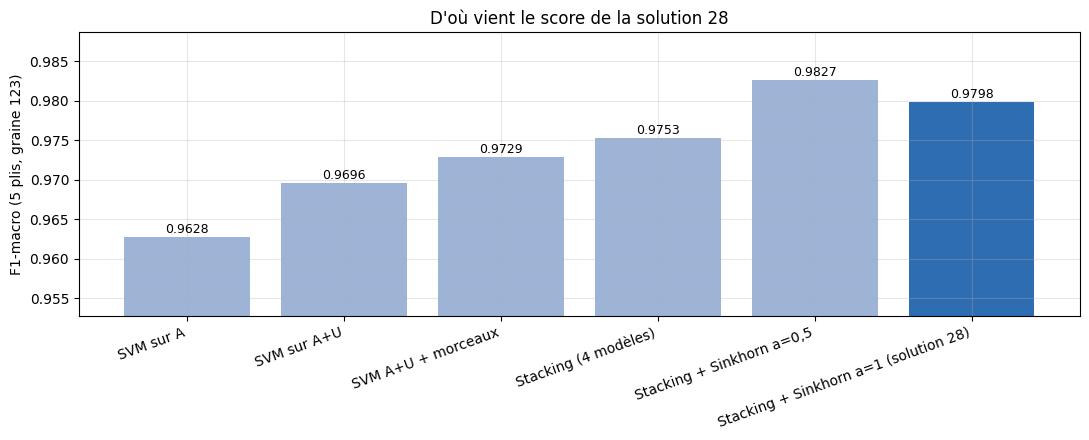

In [ ]:
summary = dict(steps)                                                         # scores des étapes précédentes
summary["Stacking + Sinkhorn a=0,5"] = S1.loc["Sinkhorn a=0.5", "moyenne"]    # variante à moitié
summary["Stacking + Sinkhorn a=1 "] = S1.loc["Sinkhorn a=1.0", "moyenne"]   # solution finale
s = pd.Series(summary)
print(s.round(4).to_string())

plt.figure(figsize=(11, 4.5))
bars = plt.bar(range(len(s)), s.values, color=["#9db4d6"] * (len(s) - 1) + ["#2f6db3"])  # dernière barre plus foncée
for i, v in enumerate(s.values):                                              # valeur au-dessus de chaque barre
    plt.text(i, v + 0.0005, f"{v:.4f}", ha="center", fontsize=9)
plt.xticks(range(len(s)), s.index, rotation=20, ha="right")                   # noms des étapes, inclinés
plt.ylim(max(0, s.min() - 0.01), min(1.0, s.max() + 0.006))                   # axe resserré pour voir les écarts
plt.ylabel("F1-macro (5 plis, graine 123)"); plt.title("D'où vient le score de la solution")
plt.tight_layout(); plt.show()

### Conclusion

| Idée | Rôle |
|---|---|
| Vues TF-IDF multiples | décrire la session de plusieurs façons complémentaires |
| **Actions entières** (`u_full`, `u_base`) | capter les enchaînements exacts, signature des habitudes |
| **Augmentation** (tiers + cinquièmes pour les rares) | donner plus d'exemples, surtout aux utilisateurs rares |
| **Stacking** (3 SVM + plus proche voisin → régression logistique) | combiner des modèles qui se trompent différemment |
| Validation croisée **imbriquée** | mesurer honnêtement, sans fuite |
| **Équilibrage de Sinkhorn** (a = 1) | corriger les hésitations en respectant la part de chaque utilisateur |

**Résultats stacking 0,9753 → avec équilibrage **0,9798** en validation croisée ; **1,000** sur le classement public Kaggle.

**Limite.** L'équilibrage suppose que l'ensemble à prédire respecte les proportions des utilisateurs du train ; le diagnostic de la section 11 le vérifie pour ce test. Sur des données tirées autrement, ou pour prédire une seule session à la fois, il faut utiliser le stacking sans équilibrage.